# Finding the stuck diodes: the two-pass diode-mask workflow

The production chain behind the archived products did not process a flight once. It processed it, looked at how
often each photodiode had been lit, called a diode **stuck** when it was lit far less often
than the rest, and processed the flight **again** with those diodes re-illuminated. This
notebook walks that loop end to end on synthetic data, with no campaign data and no
MATLAB/Octave:

1. first pass: raw → decoded image → `proc` file;
2. per-diode occupancy, two ways (`bin_stats`, and `arrayprobe.diode_report` with SPEC's
   noisy-diode test);
3. **find** the stuck diodes: `arrayprobe.masks.find_shadow_diodes`, the translation of a field-campaign variant's
   `find_shadow_diodes.m`, bug for bug, or the CLI `arrayprobe diode-masks`;
4. declare them in the run configuration (`[masking].diodes`, read into
   `RunConfig.diode_masks`);
5. second pass with the opt-in **`--diode-corrected`** (`run_flight.stage3_corrected`);
6. what changed.

**Masking is opt-in twice over.** Declaring diodes in `[masking]` does nothing by itself; the
run must also be given `--diode-corrected`, and it then writes a separate
`proc.*.diodecorrected.nc` so the fidelity-faithful default output is never shadowed.

The synthetic flight is built with `scripts/make_demo_flight.py`'s own packet helpers: forty
round particles spread across the array, and **diode 100 stuck shadowed** on every slice of
every one of them.

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page). **Related:** [17_stuck_diodes](17_stuck_diodes.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

## 1. A synthetic flight with one stuck diode

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import sys
import tempfile
from pathlib import Path

import numpy as np

from arrayprobe.tools import make_demo_flight as mdf

sys.path.insert(0, "scripts")
import run_flight  # noqa: E402

run_flight.log = lambda *a, **kw: None  # quiet the tool's own progress prints

STUCK = 100          # 1-based: the diode that reads shadowed on every slice
N_PARTICLES = 40
DIAMETER = 8


def disk_with_stuck_diode(x0, stuck0=STUCK - 1, diameter=DIAMETER):
    """One disk's run words, plus the stuck diode shadowed on every slice.

    A run word is `aa` shadowed diodes after `bb` clear ones, counted from the
    end of the previous run in the same slice.
    """
    r, c = diameter / 2, (diameter - 1) / 2
    runs = []
    for j in range(diameter):
        w = int(np.floor(np.sqrt(max(r * r - (j - c) ** 2, 0.0))))
        lo, aa = x0 + int(c) - w, 2 * w + 1
        hi = lo + aa - 1
        new = j > 0
        if stuck0 > hi:
            runs += [mdf.run_word(aa, lo, new_slice=new), mdf.run_word(1, stuck0 - hi - 1)]
        elif stuck0 < lo:
            runs += [mdf.run_word(1, stuck0, new_slice=new), mdf.run_word(aa, lo - stuck0 - 1)]
        else:
            runs.append(mdf.run_word(aa, lo, new_slice=new))
    return runs


tmp = tempfile.TemporaryDirectory()
out = Path(tmp.name)
run_flight.use_engine_35(out)               # the v3.5 engine and its stock-v3.5 profile
raw = out / "base160902060610.2DS"           # SPEC's base<YYMMDDhhmmss> convention
records = []
for k in range(N_PARTICLES):
    second = 10 + k
    header = (2016, 9, 2, 6, 6, 6, second, 250)
    x0 = 6 + (k * 23) % 110                  # spread the particles across the array
    records.append((header, mdf.image_packet(disk_with_stuck_diode(x0), DIAMETER,
                                             t_particle=0x1234ABCD + k)))
    records.append((header, mdf._hk_words(130.0, 6 * 3600 + 6 * 60 + second)))
mdf.raw_file(raw, records)
print(f"raw file: {raw.name}, {len(records)} records, diode {STUCK} stuck shadowed")

raw file: base160902060610.2DS, 80 records, diode 100 stuck shadowed


## 2. First pass: decode and process
`run_flight.stage2` and `stage3` are the same stage functions `arrayprobe run` and
`scripts/run_flight.py` call -- no mask is applied, because none has been found yet.

In [2]:
image = run_flight.stage2(raw, out)
proc = run_flight.stage3(image, out)
print(image.name)
print(proc.name)

base160902060610.H.nc
proc.base160902060610.H.nc


## 3. Per-diode occupancy, two views
`bin_stats` is what `imgProc_sm` writes: per diode, how many particle slices it counts.
**Which slices depends on the profile.** Stock UIOOPS (v3.1.4 stock and every v3.5 run, as
here) counts the **shadowed** slices, so a stuck-shadowed diode is the *maximum*; the field-campaign
fork counts the **lit** ones, so the same diode is a hole. `find_shadow_diodes` is written for
lit counts, so a shadowed count is first converted as `lit = S - shadowed`, with `S` the slice
total every diode saw. `arrayprobe.diode_report` counts the shadowed slices from the images
themselves (and gives `S`), and applies the SPEC 2D-S manual's noisy-diode test (report only
-- it repairs nothing).

40 image(s), 320 slice(s), 128 diodes
  occupancy  min 0.0000  median 0.0563  max 1.0000 (diode 100, 1-based)
SPEC noisy-diode flags (1-based): [100]


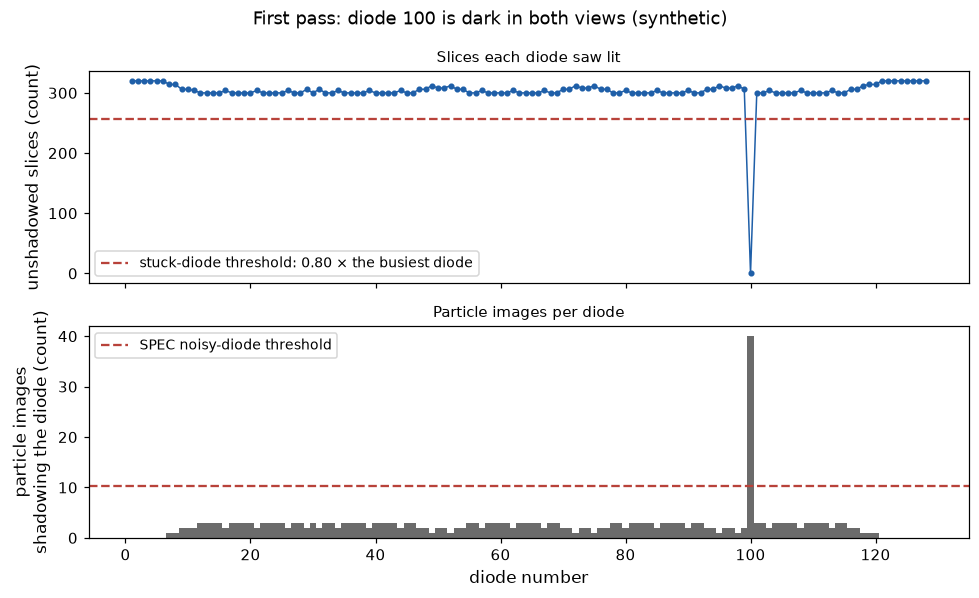

In [3]:
import matplotlib.pyplot as plt  # noqa: E402
import xarray as xr  # noqa: E402

from arrayprobe import diode_report  # noqa: E402

with xr.open_dataset(proc, mask_and_scale=False, decode_times=False) as ds:
    bin_stats = ds["bin_stats"].values.astype(float)
report = diode_report.report_from_files(image, proc)
flagged, spec_threshold, _ = diode_report.flag_noisy_diodes(report)
S = report.total_slices                    # slices every diode saw
lit = S - bin_stats                        # stock UIOOPS counts shadowed slices; the rule wants lit

diodes = np.arange(1, bin_stats.size + 1)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
ax1.plot(diodes, lit, marker=".", lw=1, color="#1f5fa8")
ax1.axhline(0.80 * lit.max(), ls="--", color="#b8423a",
            label="stuck-diode threshold: 0.80 × the busiest diode")
ax1.set_ylabel("unshadowed slices (count)")
ax1.legend(loc="lower left", fontsize=9)
ax1.set_title("Slices each diode saw lit", fontsize=10)
ax2.bar(diodes, report.images_present, width=1.0, color="#6b6b6b")
ax2.axhline(spec_threshold, ls="--", color="#b8423a", label="SPEC noisy-diode threshold")
ax2.set_ylabel("particle images\nshadowing the diode (count)")
ax2.set_xlabel("diode number")
ax2.legend(loc="upper left", fontsize=9)
ax2.set_title("Particle images per diode", fontsize=10)
fig.suptitle(f"First pass: diode {STUCK} is dark in both views (synthetic)")
fig.tight_layout()
print(report.summary())
print("SPEC noisy-diode flags (1-based):", (flagged + 1).tolist())

*Figure 1. Two views of the first pass (synthetic demo data). Top: how many slices each diode saw unshadowed, against the stuck-diode threshold of 0.80 × the busiest diode (`find_shadow_diodes.m:97`). Bottom: how many particle images shadow each diode, against the SPEC noisy-diode threshold. The stuck diode falls out in both.*

## 4. Find the stuck diodes
`masks.find_shadow_diodes` is the port of `find_shadow_diodes.m` (a field-campaign variant tree,
recovered from the dissertation; Octave-verified in `tests/test_find_shadow_diodes.py`). Its
arguments are MATLAB's -- `date`, `time`, `orientation` -- and it writes the
`diode.<date><time>.<or>.mat` MATLAB writes, next to the proc file.

The rule is **not** a flat "80% of the mean": unless some diode reads above 1.2 x mean (a
diode masked in flight), a diode is stuck below **0.80 x max**; otherwise the high ones are
replaced and the rule is 0.80 x mean. An empty result is saved as `...Hempty.mat`, a name the
second pass never loads (reported to the UIOOPS developers) -- harmless, because an empty mask changes
nothing, but easy to misread in a directory listing.

In [4]:
from arrayprobe import masks  # noqa: E402

found = masks.find_shadow_diodes("160902", "060610", "H", path=str(out) + "/", infile=proc,
                                  counts="shadowed", slice_total=S)
print("branch:", found.branch, " threshold:", found.threshold)
print("shadow_diode (1-based):", found.shadow_diode.astype(int).tolist())
print("wrote:", found.written.name)

branch: max  threshold: 256.0
shadow_diode (1-based): [100]
wrote: diode.160902060610.H.mat


The same, from the command line: `arrayprobe tune diodes` reads the engine and profile from
the proc file's stamp, converts a shadow count to lit counts itself, applies the rule, and
prints the `[masking.diodes]` line that declares the result (it writes nothing). `arrayprobe
diode-masks` reads the polarity the same way (naming it on the line it prints) and also writes the `.mat`
(`--no-write` prints the same report and writes nothing):

```bash
arrayprobe tune diodes --proc proc.base160902060610.H.nc
```

In [5]:
import os  # noqa: E402

from arrayprobe import cli  # noqa: E402

here = Path.cwd()
os.chdir(out)                      # so the printed paths are the file names
try:
    status = cli.main(["tune", "diodes", "--proc", proc.name])
finally:
    os.chdir(here)
print("exit status", status)

proc.base160902060610.H.nc: engine 3.5 (stamp (driver)), profile stock-v3.5
  bin_stats counts: shadowed, converted lit = S - shadow, S=320 (offset 0, every 128-diode probe in PROBES_V35 (HVPS, 2DS, 3VCPI_H, 3VCPI_V))
  rule: branch max, threshold 256 (find_shadow_diodes.m:97 (a < int32(STUCK_FRACTION*max(a))))
  diodes over 1.2 x mean: none
  flagged: [100]
  diode      lit   of max  of mean
    100        0    0.000    0.000  flagged
  run-file lines (apply with --diode-corrected):
    [masking.diodes]
    "base160902060610" = [100]
exit status 0


## 5. Declare the mask, then the second pass with `--diode-corrected`
The mask goes into the run configuration under `[masking].diodes`, keyed by the raw file's
stem. On the command line the second pass is

```bash
python scripts/run_flight.py --preset DEMO_2DS_H --engine 3.5 --tas-file ../base160101000000.aircraft.cdf --config run.toml --diode-corrected ../base160101000000.2DS
```

and without `--diode-corrected` the declared mask **stays unused** -- `run_flight` logs so
and writes the ordinary output. In-process, `--diode-corrected` is
`run_flight.stage3_corrected`, fed from the same `SHADOW_DIODE_OVERRIDES` table the
command line fills from the config.

In [6]:
from arrayprobe.config import load_config  # noqa: E402

mask_list = ", ".join(str(int(d)) for d in found.shadow_diode)
toml = out / "run.toml"
toml.write_text('[fidelity]\nprofile = "stock-v3.5"\n\n'
                f"[masking]\ndiodes = {{ {raw.stem} = [{mask_list}] }}\n", encoding="utf-8")
cfg = load_config(toml)
print(toml.read_text(encoding="utf-8").strip())
print("RunConfig.diode_masks:", cfg.diode_masks)

for stem, diodes_ in cfg.diode_masks.items():      # what --diode-corrected consumes
    run_flight.SHADOW_DIODE_OVERRIDES[stem] = list(diodes_)
proc_corrected = run_flight.stage3_corrected(image, out)
print(proc_corrected.name)

[fidelity]
profile = "stock-v3.5"

[masking]
diodes = { base160902060610 = [100] }
RunConfig.diode_masks: {'base160902060610': (100,)}
proc.base160902060610.H.diodecorrected.nc


## 6. What changed
`imgProc_sm` re-illuminates the listed diodes (`c(:,shadow_diode)='1'`) before habit,
rejection and sizing run, so the correction reaches every written variable: the particles
lose the stray shadowed column that was stretching them across the array.

first pass       particles  40  median width  42.0 diodes  accepted   5  bin_stats[100] = 320
diode-corrected  particles  40  median width   7.0 diodes  accepted  40  bin_stats[100] = 0


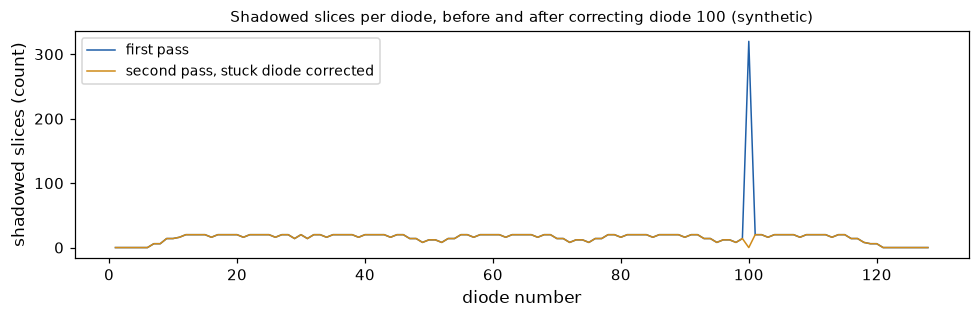

In [7]:
def summarise(path):
    with xr.open_dataset(path, mask_and_scale=False, decode_times=False) as ds:
        v = {k: ds[k].values for k in ("image_width", "image_auto_reject", "bin_stats")}
    return v


first, second = summarise(proc), summarise(proc_corrected)
for label, v in (("first pass", first), ("diode-corrected", second)):
    accepted = int(np.sum(v["image_auto_reject"] == ord("0")))
    print(f"{label:16s} particles {v['image_width'].size:3d}  "
          f"median width {np.median(v['image_width']):5.1f} diodes  "
          f"accepted {accepted:3d}  bin_stats[{STUCK}] = {int(v['bin_stats'][STUCK - 1])}")

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(diodes, first["bin_stats"], lw=1, label="first pass", color="#1f5fa8")
ax.plot(diodes, second["bin_stats"], lw=1, label="second pass, stuck diode corrected", color="#d08b1a")
ax.set_xlabel("diode number")
ax.set_ylabel("shadowed slices (count)")
ax.set_title(f"Shadowed slices per diode, before and after correcting diode {STUCK} (synthetic)", fontsize=10)
ax.legend(fontsize=9)
fig.tight_layout()

*Figure 2. Shadowed slices per diode in the first pass and in the second pass run with the stuck diode corrected (`--diode-corrected`; synthetic demo data).*

## Where this sits

* **Faithful, including its blind spot.** The whole-file criterion cannot see a diode that
  is stuck for a few minutes of a long flight (reported to the UIOOPS developers); `diode_report` and the
  gallery are the tools for that, and both only report.
* **The `.mat` is MATLAB's**, workspace and all (`a`, `date`, `orientation`, `path`,
  `shadow_diode`, `time`), so a file written here loads in MATLAB, and
  `masks.load_shadow_diode_mask` reads the archived originals.
* Opt-ins named in this notebook: **`--diode-corrected`** (second pass), and the
  `[masking].diodes` declaration it consumes.

In [8]:
tmp.cleanup()
print("scratch directory removed")

scratch directory removed
